# 01 · Exploratory data analysis of the raw sources

Exploration only - no production logic lives here. Findings from this notebook drive the silver cleaning rules in `utils/transformation/build_silver.py` and the join design in `utils/features/feature_store.py`. Sections 4-7 back the model design: excluding clickstream, the temporal split, the main drivers and the 30-DPD label.

In [1]:
import pandas as pd
import numpy as np
pd.set_option('display.width', 200)

lms = pd.read_csv('../data/lms_loan_daily.csv')
attributes = pd.read_csv('../data/features_attributes.csv', dtype=str)
financials = pd.read_csv('../data/features_financials.csv', dtype=str)
clickstream = pd.read_csv('../data/feature_clickstream.csv')

for name, df in [('lms_loan_daily', lms), ('attributes', attributes), ('financials', financials), ('clickstream', clickstream)]:
    print(f"{name:15s} rows={len(df):>7,}  customers={df.Customer_ID.nunique():>6,}  snapshots {df.snapshot_date.min()} .. {df.snapshot_date.max()}")

lms_loan_daily  rows=137,500  customers=12,500  snapshots 2023-01-01 .. 2025-11-01
attributes      rows= 12,500  customers=12,500  snapshots 2023-01-01 .. 2025-01-01
financials      rows= 12,500  customers=12,500  snapshots 2023-01-01 .. 2025-01-01
clickstream     rows=215,376  customers= 8,974  snapshots 2023-01-01 .. 2024-12-01


## 1. Grain and join key
Attributes and financials hold **one row per customer**, and that row's `snapshot_date` equals the customer's `loan_start_date`. The application date is therefore a leakage-free join key between features and labels.

In [2]:
loan_starts = lms[lms.installment_num == 0][['Customer_ID', 'loan_start_date']]
m = loan_starts.merge(attributes[['Customer_ID', 'snapshot_date']], on='Customer_ID')
print('attribute snapshot == loan start date:', (m.snapshot_date == m.loan_start_date).mean())

m = loan_starts.merge(clickstream[['Customer_ID', 'snapshot_date']], left_on=['Customer_ID', 'loan_start_date'], right_on=['Customer_ID', 'snapshot_date'], how='left')
print('loans with clickstream in the application month:', round(m.snapshot_date.notna().mean(), 3))

attribute snapshot == loan start date: 1.0
loans with clickstream in the application month: 0.718


## 2. Dirty values in attributes and financials

In [3]:
def to_num(s):
    return pd.to_numeric(s.str.replace('_', '', regex=False).str.strip(), errors='coerce')

print('ages with a stray "_":', attributes.Age.str.contains('_').sum())
age = to_num(attributes.Age)
print('ages outside 14-100:', (~age.between(14, 100)).sum(), '| min', age.min(), 'max', age.max())
print('placeholder occupations:', (attributes.Occupation == '_______').sum())
print('malformed SSNs:', (~attributes.SSN.str.match(r'^\d{3}-\d{2}-\d{4}$')).sum())

ages with a stray "_": 637
ages outside 14-100: 319 | min -500 max 8678
placeholder occupations: 880
malformed SSNs: 703


In [4]:
rows = []
for col in financials.columns.drop(['Customer_ID', 'snapshot_date', 'Type_of_Loan', 'Credit_History_Age']):
    s = financials[col].astype(str)
    non_numeric = s[~s.str.match(r'^-?\d+(\.\d+)?$')]
    rows.append((col, len(non_numeric), non_numeric.value_counts().head(3).to_dict()))
pd.DataFrame(rows, columns=['column', 'non-numeric values', 'most common']).query('`non-numeric values` > 0')

,column,non-numeric values,most common
0,Annual_Income,859,"{'40380.18_': 1, '52312.68_': 1, '49718.55_': 1}"
5,Num_of_Loan,623,"{'2_': 110, '4_': 105, '3_': 79}"
7,Num_of_Delayed_Payment,374,"{'18_': 25, '19_': 24, '20_': 23}"
8,Changed_Credit_Limit,254,{'_': 254}
10,Credit_Mix,12500,"{'Standard': 4497, 'Good': 3032, '_': 2611}"
11,Outstanding_Debt,139,"{'2699.17_': 1, '642.42_': 1, '755.17_': 1}"
13,Payment_of_Min_Amount,12500,"{'Yes': 6571, 'No': 4491, 'NM': 1438}"
15,Amount_invested_monthly,558,{'__10000__': 558}
16,Payment_Behaviour,12500,"{'Low_spent_Small_value_payments': 3202, 'High..."
17,Monthly_Balance,1,{'__-333333333333333333333333333__': 1}


In [5]:
numeric = ['Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Num_Credit_Inquiries', 'Annual_Income', 'Total_EMI_per_month']
financials[numeric].apply(to_num).quantile([0, .01, .5, .95, .99, 1]).T.round(1)

,0.00,0.01,0.50,0.95,0.99,1.00
Num_Bank_Accounts,-1.0,0.0,6.0,10.0,511.0,1756.0
Num_Credit_Card,0.0,1.0,5.0,10.0,878.0,1499.0
Interest_Rate,1.0,1.0,14.0,33.0,2865.0,5789.0
Num_of_Loan,-100.0,-100.0,3.0,8.0,9.0,1495.0
Num_of_Delayed_Payment,-3.0,0.0,14.0,24.0,27.0,4293.0
Num_Credit_Inquiries,0.0,0.0,6.0,14.0,946.5,2554.0
Annual_Income,7005.9,7542.4,37572.4,134316.5,178815.7,23834698.0
Total_EMI_per_month,0.0,0.0,72.9,592.3,57478.9,81971.0


The 99th-100th percentiles show corrupted outliers (e.g. 1,756 bank accounts, 5,789% interest). Silver nulls values outside a fixed plausible range rather than clipping to a percentile - a percentile computed on all data would leak test information.

In [6]:
ratio = to_num(financials.Annual_Income) / (12 * to_num(financials.Monthly_Inhand_Salary))
print('annual income / (12 x monthly salary) quantiles:', ratio.quantile([.5, .95, .99]).round(2).to_dict())
print('incomes > 3x annual salary:', (ratio > 3).sum())
print('EMI > monthly salary:', (to_num(financials.Total_EMI_per_month) > to_num(financials.Monthly_Inhand_Salary)).sum())

annual income / (12 x monthly salary) quantiles: {0.5: 1.0, 0.95: 1.22, 0.99: 1.7}
incomes > 3x annual salary: 114
EMI > monthly salary: 397


In [7]:
types = financials.Type_of_Loan.fillna('')
listed = types.apply(lambda s: 0 if s == '' else len(s.split(',')))
print('Num_of_Loan equals number of listed loan types (valid rows):')
pd.crosstab(to_num(financials.Num_of_Loan).clip(-1, 10), listed)

Num_of_Loan equals number of listed loan types (valid rows):


Type_of_Loan,0,1,2,3,4,5,6,7,8,9
Num_of_Loan,,,,,,,,,,
-1,53,60,75,72,77,42,37,40,17,27
0,1363,0,0,0,0,0,0,0,0,0
1,0,1324,0,0,0,0,0,0,0,0
2,0,0,1879,0,0,0,0,0,0,0
3,0,0,0,1887,0,0,0,0,0,0
4,0,0,0,0,1844,0,0,0,0,0
5,0,0,0,0,0,894,0,0,0,0
6,0,0,0,0,0,0,976,0,0,0
7,0,0,0,0,0,0,0,916,0,0


## 3. Label balance

In [8]:
mob6 = lms[lms.installment_num == 6].copy()
mob6['installments_missed'] = np.ceil(mob6.overdue_amt / mob6.due_amt.replace(0, np.nan)).fillna(0)
print('share of loans with any overdue amount at MOB 6:', round((mob6.overdue_amt > 0).mean(), 3))

share of loans with any overdue amount at MOB 6: 0.288


## 4. Clickstream coverage over time
Clickstream is the only source that does not cover every loan. Check *which* loans have it.

customers with clickstream: 8974 | loans before 2024-07: 8974
months per customer: median 24.0 | first month 2023-01-01 | last month 2024-12-01


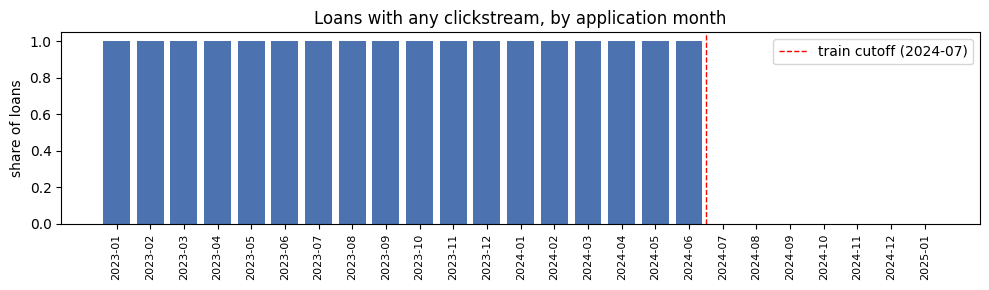

In [9]:
import matplotlib.pyplot as plt

starts = lms[lms.installment_num == 0][['Customer_ID', 'loan_start_date']].copy()
starts['month'] = starts.loan_start_date.str[:7]
starts['has_clickstream'] = starts.Customer_ID.isin(set(clickstream.Customer_ID))
coverage = starts.groupby('month').has_clickstream.mean()

per_customer = clickstream.groupby('Customer_ID').snapshot_date.agg(['min', 'max', 'count'])
print('customers with clickstream:', len(per_customer), '| loans before 2024-07:', (starts.loan_start_date < '2024-07-01').sum())
print('months per customer: median', per_customer['count'].median(),
      '| first month', per_customer['min'].min(), '| last month', per_customer['max'].max())

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(coverage.index, coverage.values, color=['#4C72B0' if m < '2024-07' else '#DD8452' for m in coverage.index])
ax.axvline(coverage.index.get_loc('2024-07') - 0.5, color='red', ls='--', lw=1, label='train cutoff (2024-07)')
ax.set_ylabel('share of loans'); ax.set_title('Loans with any clickstream, by application month')
ax.tick_params(axis='x', rotation=90, labelsize=8); ax.legend(); plt.tight_layout(); plt.show()

**Finding.** Every loan that started before Jul 2024 has clickstream, for all 24 months (Jan 2023 – Dec 2024), and no loan from Jul 2024 onward has any. The training window has it and every out-of-time loan does not, so a model would learn from it and then score every new applicant with it blank. `fe_1..fe_20` and `has_clickstream` stay in the feature store but are excluded from the model inputs (`ml.exclude_features` in `config/base.yaml`).

## 5. Bad rate over time
Label as in the label store: 30+ days past due at month-on-book 6, by application month.

bad rate overall 0.288 | train window 0.289 | test window 0.287
monthly range 0.246 - 0.331


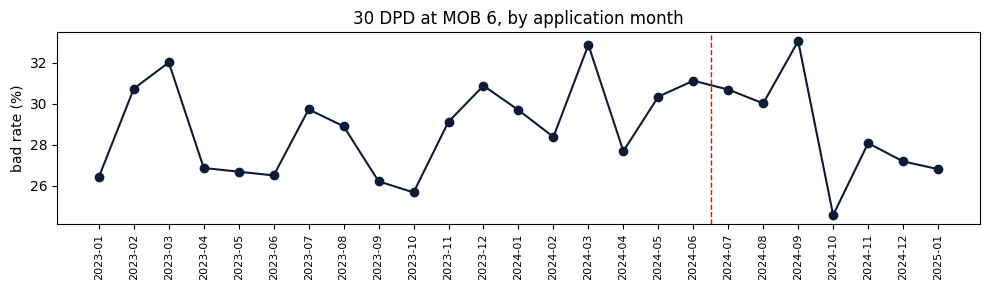

In [10]:
snap = pd.to_datetime(mob6.snapshot_date)
first_missed = pd.to_datetime([s - pd.DateOffset(months=int(n)) for s, n in zip(snap, mob6.installments_missed)])
mob6['dpd'] = np.where(mob6.overdue_amt > 0, (snap.values - first_missed.values) / np.timedelta64(1, 'D'), 0).astype(int)
mob6['label'] = (mob6.dpd >= 30).astype(int)
mob6['month'] = mob6.loan_start_date.str[:7]

bad_rate = mob6.groupby('month').label.mean()
train, test = mob6[mob6.loan_start_date < '2024-07-01'], mob6[mob6.loan_start_date >= '2024-07-01']
print(f'bad rate overall {mob6.label.mean():.3f} | train window {train.label.mean():.3f} | test window {test.label.mean():.3f}')
print(f'monthly range {bad_rate.min():.3f} - {bad_rate.max():.3f}')

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(bad_rate.index, bad_rate.values * 100, marker='o', color='#0F1B35')
ax.axvline(bad_rate.index.get_loc('2024-07') - 0.5, color='red', ls='--', lw=1)
ax.set_ylabel('bad rate (%)'); ax.set_title('30 DPD at MOB 6, by application month')
ax.tick_params(axis='x', rotation=90, labelsize=8); plt.tight_layout(); plt.show()

**Finding.** The bad rate is stable: 28.9% in the training window, 28.7% in the test window, between 24.6% and 33.1% in any single month. There is no label drift to correct for, and a temporal train/test split is fair.

## 6. Strongest raw signals
Bad rate by decile for three financial fields, after the same cleaning silver applies.

Outstanding_Debt       bad rate lowest decile 0.122 -> highest 0.462
Interest_Rate          bad rate lowest decile 0.155 -> highest 0.591
Delay_from_due_date    bad rate lowest decile 0.119 -> highest 0.587


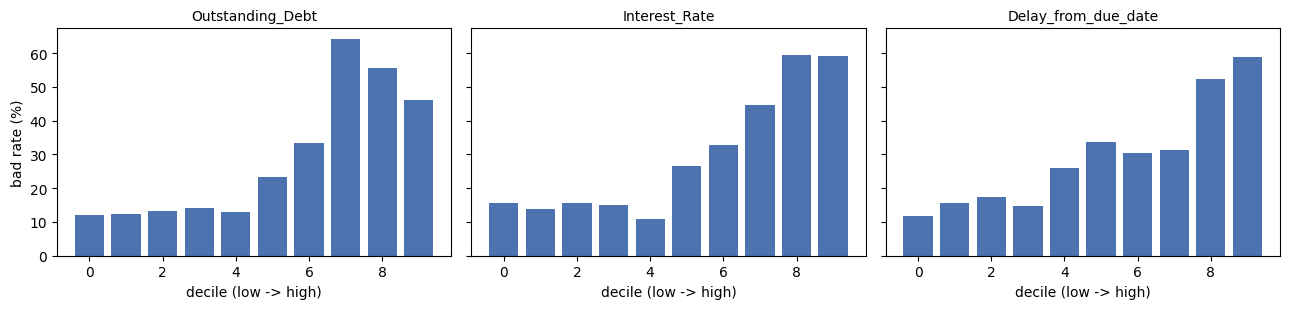

In [11]:
fin = financials[['Customer_ID', 'Outstanding_Debt', 'Interest_Rate', 'Delay_from_due_date']].copy()
fin['Outstanding_Debt'] = to_num(fin.Outstanding_Debt)
fin['Interest_Rate'] = to_num(fin.Interest_Rate).where(lambda s: s.between(0, 50))
fin['Delay_from_due_date'] = to_num(fin.Delay_from_due_date)
joined = fin.merge(mob6[['Customer_ID', 'label']], on='Customer_ID')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, column in zip(axes, ['Outstanding_Debt', 'Interest_Rate', 'Delay_from_due_date']):
    deciles = pd.qcut(joined[column], 10, duplicates='drop')
    rate = joined.groupby(deciles, observed=True).label.mean()
    ax.bar(range(len(rate)), rate.values * 100, color='#4C72B0')
    ax.set_title(column, fontsize=10); ax.set_xlabel('decile (low -> high)')
    print(f'{column:22s} bad rate lowest decile {rate.iloc[0]:.3f} -> highest {rate.iloc[-1]:.3f}')
axes[0].set_ylabel('bad rate (%)'); plt.tight_layout(); plt.show()

**Finding.** All three fields separate good and bad loans strongly and monotonically: the bad rate rises from 12.2% to 46.2% across `Outstanding_Debt` deciles, 15.5% to 59.1% for `Interest_Rate` and 11.9% to 58.7% for `Delay_from_due_date`. These are the model's top drivers too (SHAP), and the debt and income ratios in gold build on them.

## 7. Days past due at MOB 6
Why the label cut-off is 30 DPD.

In [12]:
overdue = mob6[mob6.overdue_amt > 0]
print('loans overdue at MOB 6:', len(overdue), f'({len(overdue) / len(mob6):.3f})')
print('installments missed:', overdue.installments_missed.astype(int).value_counts().sort_index().to_dict())
print('DPD range among overdue loans:', overdue.dpd.min(), '-', overdue.dpd.max())
for cut in (1, 30, 60, 90):
    print(f'share of all loans with DPD >= {cut:>2}: {(mob6.dpd >= cut).mean():.3f}')

loans overdue at MOB 6: 3602 (0.288)
installments missed: {2: 681, 3: 1133, 4: 1115, 5: 541, 6: 132}
DPD range among overdue loans: 59 - 184
share of all loans with DPD >=  1: 0.288
share of all loans with DPD >= 30: 0.288
share of all loans with DPD >= 60: 0.284
share of all loans with DPD >= 90: 0.230


**Finding.** No loan is only slightly late at MOB 6: every overdue loan has missed at least 2 instalments (59–184 DPD). A 30-DPD cut-off therefore equals "in arrears at all" (28.8%), and 60 DPD gives almost the same label (28.4%); only 90 DPD changes it (23.0%). 30 DPD at MOB 6 is the standard early-default definition and loses nothing here.